# Lab 24: Experiments and Calibration

This lab fits the reference Bayesian MMM from Lab 15 to the Sedge Shoes national aggregate, then calibrates its estimate for one channel, Paid Search, against a simulated incrementality experiment.
Lab 23 showed that this national-aggregate fit can land well away from the truth for some channels, because aggregation throws away the regional variation and each channel's half-saturation point is computed from the national series rather than the regional ones the data were built from.
An experiment gives a second, largely independent read on one channel, which a Bayesian model can combine with the observational fit rather than choose between.
It accompanies Chapter 24 of the book Marketing Mix Modelling.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pymc as pm

from mmm_book import RANDOM_SEED
from mmm_book.plotting import mmm_style
from mmm_book.reference import REVENUE_SCALE, build_features, national_aggregate, reference_model
from mmm_book.sedge import GROUND_TRUTH, generate_sedge

mmm_style()

SAMPLE_KWARGS = dict(
    draws=1000,
    tune=1000,
    chains=4,
    cores=1,
    target_accept=0.95,
    random_seed=RANDOM_SEED,
    progressbar=False,
)


def check(idata):
    n_divergent = int(idata.sample_stats["diverging"].sum())
    r_hat = float(az.summary(idata, kind="diagnostics")["r_hat"].max())
    print(f"divergent transitions: {n_divergent}, largest r_hat: {r_hat:.3f}")

## Fitting the observational model

This reuses the shared national-aggregate reference model from `mmm_book.reference`, the model Lab 15 builds with the priors Lab 17 chooses.
Sampling uses the settings every lab uses (four chains of 1,000 draws after 1,000 warm-up steps, target acceptance 0.95), and the cell checks the fit before anything is read from it.

In [2]:
df = generate_sedge()
nat = national_aggregate(df)

with reference_model(nat):
    idata = pm.sample(**SAMPLE_KWARGS)
check(idata)

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [intercept, trend, season_a, season_b, omega_launch, delta_promo, gamma_log_price, gamma_distribution, gamma_stock, gamma_temperature, gamma_rainfall, gamma_category, beta_tv, beta_search, beta_meta, beta_youtube, beta_ooh, sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 25 seconds.


divergent transitions: 0, largest r_hat: 1.004


## The observational estimate for Search

Lab 23's recovery check found Search's ROAS above `GROUND_TRUTH['search']` on this same fit, with a wide interval.
Each posterior draw of `beta_search` converts into a ROAS through the Search feature's total and the total Search spend.

In [3]:
feat = build_features(nat)
feat_search_total = float(feat["search"].sum())
spend_search_total = float(nat["search_spend"].to_numpy(dtype=float).sum())
roas_per_beta = feat_search_total * REVENUE_SCALE / spend_search_total


def describe(label, draws):
    lo, hi = np.percentile(draws, [5, 95])
    print(f"{label:<28}mean {draws.mean():.2f}, 90% interval {lo:.2f} to {hi:.2f}")


roas_search_obs = idata.posterior["beta_search"].to_numpy().reshape(-1) * roas_per_beta
describe("observational Search ROAS:", roas_search_obs)
print(f"ground truth Search ROAS:   {GROUND_TRUTH['search']:.2f}")

observational Search ROAS:  mean 3.10, 90% interval 0.74 to 5.54
ground truth Search ROAS:   2.70


## Adding an experiment result

Suppose a geo experiment measured Search's ROAS directly, from deliberate variation in spend rather than from the observational data the model was fitted to.
The result is simulated here as one noisy draw around the true `GROUND_TRUTH['search']` with the experiment's standard error, `experiment_se`; in a real analysis the truth would be unknown and only the noisy result would be seen.

Chapter 24 keeps two kinds of uncertainty apart.
The standard error $\text{SE}$ is the experiment's own.
Transport uncertainty, $\sigma_{\text{transport}}$, is the team's judgement of how far the quantity could differ between the experiment's setting and the model's: here the test is imagined to have run for eight weeks in the spring, while the model's ROAS averages three years.
The team sets $\sigma_{\text{transport}}$ before seeing how the model responds, and the likelihood uses the widened $\sigma_{\text{eff}} = \sqrt{\text{SE}^2 + \sigma_{\text{transport}}^2}$.

The experiment enters the model as one extra likelihood term: the ROAS it measured is treated as a noisy reading of the ROAS the model implies, `experiment_roas_obs ~ Normal(implied ROAS, sigma_eff)`.
The book writes the same likelihood on the lift in pounds; a result reported as a ROAS is the same evidence, since multiplying the ROAS, its standard error and the transport term by the change in spend turns each into pounds.
`reference_model` returns the model before sampling for exactly this kind of extension: entering its context again with `with` and adding new variables leaves everything already built in place.

In [4]:
rng = np.random.default_rng(RANDOM_SEED)
experiment_se = 0.3
sigma_transport = 0.2
sigma_eff = float(np.sqrt(experiment_se**2 + sigma_transport**2))
experiment_roas = float(GROUND_TRUTH["search"] + rng.normal(0, experiment_se))
print(f"experiment result: Search ROAS {experiment_roas:.2f}, SE {experiment_se}")
print(f"transport judgement: {sigma_transport}, so sigma_eff = {sigma_eff:.2f}")

model_calibrated = reference_model(nat)
with model_calibrated:
    implied_search_roas = pm.Deterministic(
        "implied_search_roas", model_calibrated["beta_search"] * roas_per_beta
    )
    pm.Normal(
        "experiment_roas_obs", mu=implied_search_roas, sigma=sigma_eff, observed=experiment_roas
    )

experiment result: Search ROAS 2.79, SE 0.3
transport judgement: 0.2, so sigma_eff = 0.36


## Sampling the calibrated model

The calibrated model is sampled with the same settings as the observational fit above.

In [5]:
with model_calibrated:
    idata_calibrated = pm.sample(**SAMPLE_KWARGS)
check(idata_calibrated)

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [intercept, trend, season_a, season_b, omega_launch, delta_promo, gamma_log_price, gamma_distribution, gamma_stock, gamma_temperature, gamma_rainfall, gamma_category, beta_tv, beta_search, beta_meta, beta_youtube, beta_ooh, sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 17 seconds.


divergent transitions: 0, largest r_hat: 1.003


## Before and after calibration

Comparing the observational-only posterior for Search's ROAS with the calibrated one shows a shift towards the experiment result and a narrowing, because the experiment adds information the observational data alone did not have.

In [6]:
roas_search_calibrated = idata_calibrated.posterior["implied_search_roas"].to_numpy().reshape(-1)

describe("observational Search ROAS:", roas_search_obs)
describe("calibrated Search ROAS:", roas_search_calibrated)
print(f"experiment result:          {experiment_roas:.2f} (sigma_eff {sigma_eff:.2f})")
print(f"ground truth:               {GROUND_TRUTH['search']:.2f}")

observational Search ROAS:  mean 3.10, 90% interval 0.74 to 5.54
calibrated Search ROAS:     mean 2.79, 90% interval 2.22 to 3.37
experiment result:          2.79 (sigma_eff 0.36)
ground truth:               2.70


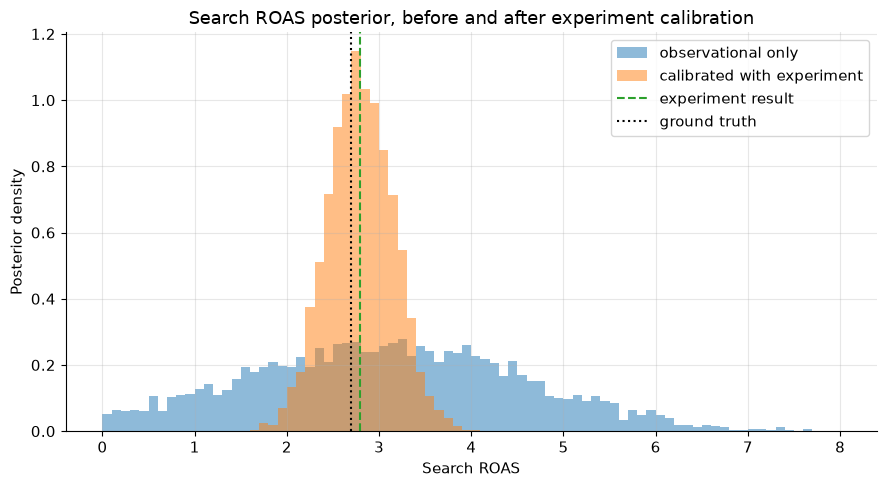

In [7]:
fig, ax = plt.subplots()
bins = np.linspace(0, 8, 81)
ax.hist(roas_search_obs, bins=bins, density=True, alpha=0.5, label="observational only")
ax.hist(
    roas_search_calibrated, bins=bins, density=True, alpha=0.5, label="calibrated with experiment"
)
ax.axvline(experiment_roas, color="C2", linestyle="--", label="experiment result")
ax.axvline(GROUND_TRUTH["search"], color="k", linestyle=":", label="ground truth")
ax.set_xlabel("Search ROAS")
ax.set_ylabel("Posterior density")
ax.set_title("Search ROAS posterior, before and after experiment calibration")
ax.legend()
fig.tight_layout()

## What the design measures: a holdout versus a push

An experiment's number depends on its design.
A holdout (switch spend off) measures the return on the spend that was switched off, an average-type return for that slice.
A push (add spend) measures the return on the extra pounds, a marginal-type return near the starting level, which on a concave curve cannot exceed the marginal return there.
The Chapter 36 Meta experiment is a holdout: eight regions pause Meta for six weeks while matched regions carry on, and lost revenue is measured over the six weeks plus a two-week cooldown so that adstock carryover is counted.
The cell below recomputes both designs from the Sedge ledger response curve for the same eight regions: the holdout and, for contrast, a push that lifts the same regions from about 13,000 to 43,000 pounds a week.

In [8]:
from mmm_book.experiment import ledger_holdout_design, ledger_push_design
from mmm_book.sedge import true_marginal_roas

holdout = ledger_holdout_design()
push = ledger_push_design()
marginal_meta = true_marginal_roas()["meta"]

print(f"meta marginal ROAS at current spend:  {marginal_meta:.2f}")
print(
    f"holdout: {holdout['withheld_spend']:,.0f} withheld, lift {holdout['expected_lift']:,.0f}, "
    f"ROAS {holdout['expected_roas']:.2f}"
)
print(
    f"push:    {push['extra_spend']:,.0f} extra, revenue {push['extra_revenue']:,.0f}, "
    f"ROAS {push['roas']:.2f}"
)
print(f"meta average ROAS (ledger):           {GROUND_TRUTH['meta']:.2f}")
assert push["roas"] < holdout["expected_roas"] < GROUND_TRUTH["meta"]

meta marginal ROAS at current spend:  0.90
holdout: 77,223 withheld, lift 120,028, ROAS 1.55
push:    180,777 extra, revenue 84,709, ROAS 0.47
meta average ROAS (ledger):           1.75


## Takeaway

The observational fit alone puts Search's ROAS at 3.10 against the 2.7 ledger value, with a 90 per cent interval from 0.74 to 5.54 that is too wide to plan with, consistent with Lab 23's recovery check: a national-aggregate model has little to separate Search's effect from the category demand its spend follows.
Adding the experiment as an extra likelihood term does not overrule the observational data; it combines with it.
The calibrated posterior (mean 2.79, 90 per cent interval 2.22 to 3.37) sits close to the experiment result and is far narrower than the observational one, because the experiment, even widened for transport to an effective standard deviation of 0.36, is much more precise than the observational fit.
The transport term is a judgement, recorded before the model ran, and it decides how hard the experiment pulls: setting it to zero would treat a spring test as if it measured the three-year average exactly.
A well-designed experiment anchors the handful of channels it can reach, and the channels it cannot reach still rely on the observational fit, which is why Lab 23's identifiability warnings, particularly around collinear channels, matter most for the channels calibration cannot cover.
The design matters as much as the arithmetic: the same Meta curve gives a holdout return well above its marginal return and a push return well below it, so an experiment is only comparable with the MMM once its estimand is aligned.